In [53]:
print("In the name of Allah")

In the name of Allah


In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    r2_score,
    mean_squared_error,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    average_precision_score
)

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN


#ML FINAL EXAM

### Email: akibhasan011@gmail.com

Task: Copy this notebook on your drive and answer in that copy

Choose a dataset of your choice from kaggle or UCI

Some suggestions:https://www.kaggle.com/datasets/ahmettezcantekin/beginner-datasets

You may choose a dataset of your choice too

In this exam:
1. Provide code and explaination(in text cell) whenever needed and you must show the outputs
2. Before submitting run all cells and make sure the outputs are visible


In [55]:
from sklearn.datasets import load_breast_cancer

df = load_breast_cancer(as_frame = True).frame

In [56]:
df.head(5)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 0. Dataset overview

Why you choose this dataset and what did you observe from the dataset description



  

I chose the Breast Cancer Wisconsin Diagnostic Dataset because it is a real world healthcare dataset & a good example of a classification problem. The features are extracted from FNA images of breast mases and describe cell nucleus characteristics. The main goal is to predict whether a tumor is malignant or benign using these measurements.

## Answer:



# 1. Dataset description (15 marks)


### Dataset Description
1. How many features?
2. Classification or regression problem? Why do you think so?
3. How many data points?
4. Is there any null values?
5. What kind of features are in your dataset? (Quantitative / Categorical)
6. Do you need to encode the categorical variables, why or why not?
7. Correlation of all the features, What do you understand after the correlation test?
8. Perform exploratory data analysis to extract some important relationships from your data.


Provide necessary codes and explanation

In [57]:
print(f"Shape of the dataset : {df.shape}")

print(df['target'].unique())

print(f"Null values : {( df.isnull().sum() > 0 ).sum()}")

Shape of the dataset : (569, 31)
[0 1]
Null values : 0


In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

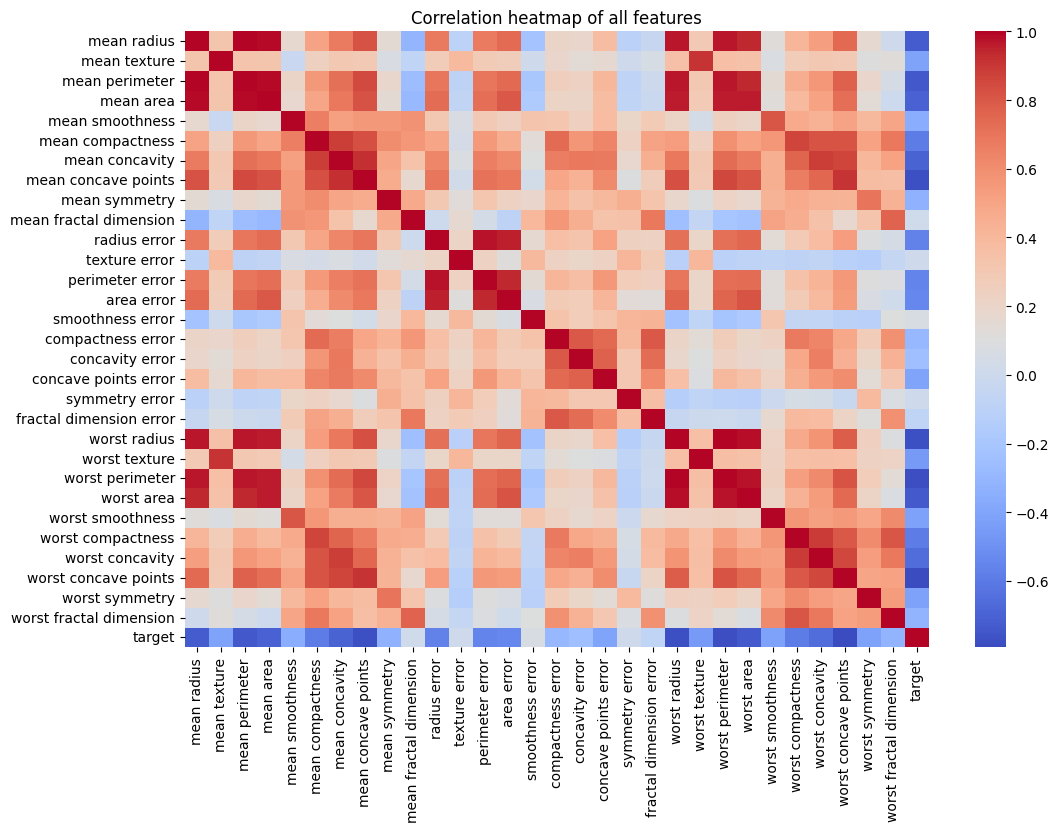

In [59]:
plt.figure( figsize = ( 12, 8 ) )

sns.heatmap( df.corr(), cmap = 'coolwarm' )

plt.title("Correlation heatmap of all features")
plt.show()

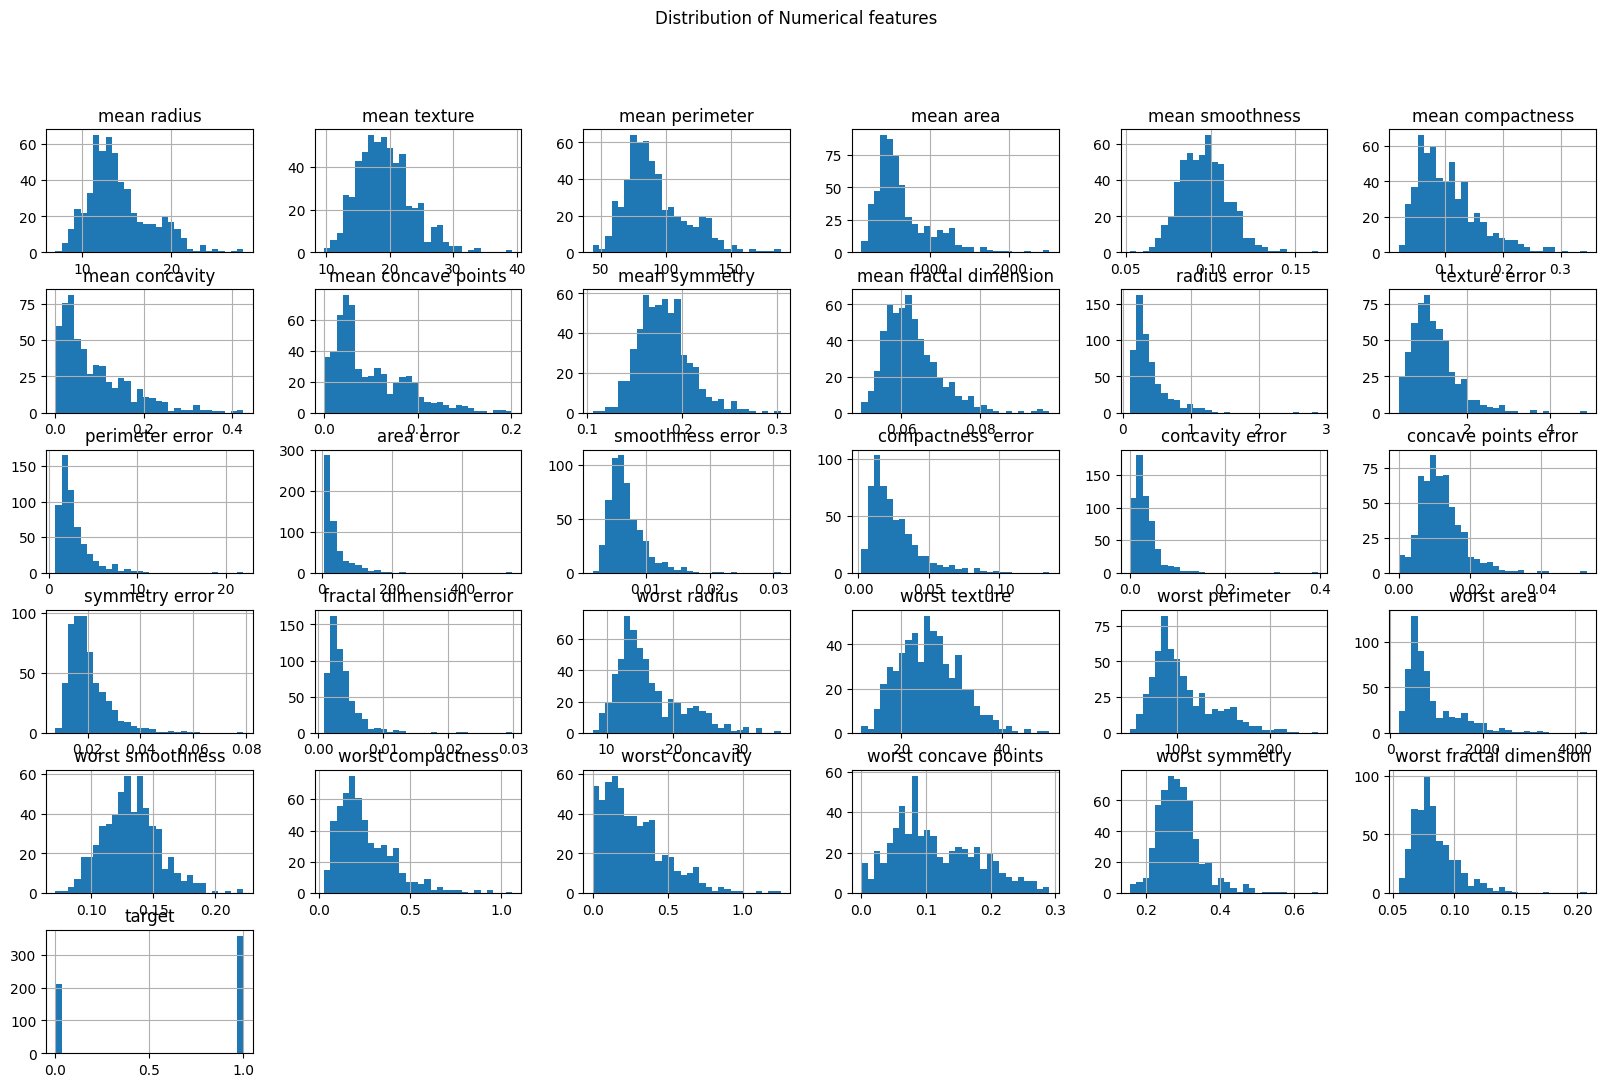

In [60]:
df.hist( figsize = (20, 12), bins = 30 )

plt.suptitle('Distribution of Numerical features')
plt.show()

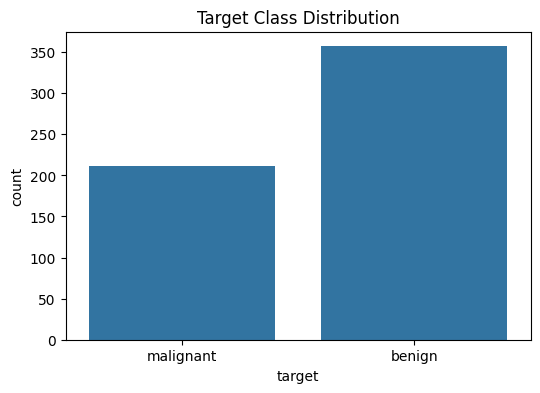

In [61]:
plt.figure(figsize = (6, 4))

sns.countplot( data = df, x = df['target'].map({0 : 'malignant', 1 : 'benign'}) )
plt.title("Target Class Distribution")

plt.show()

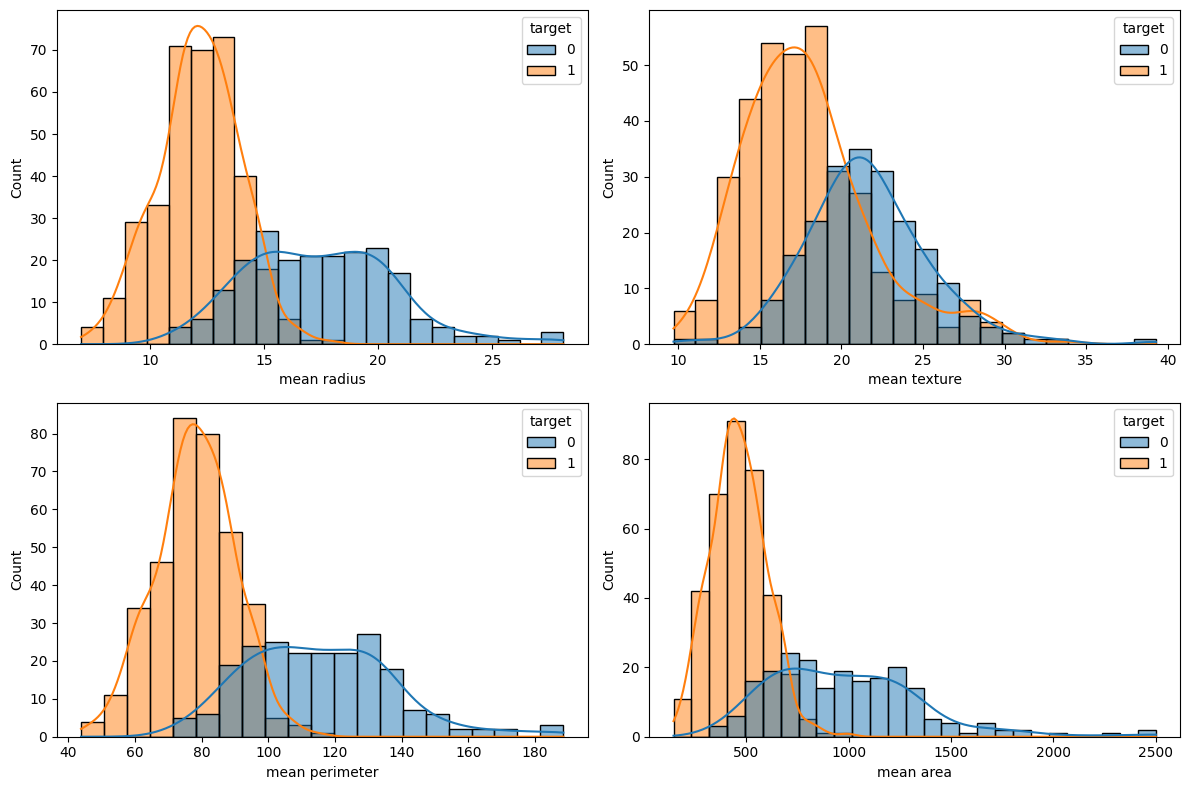

In [62]:
plt.figure( figsize = ( 12, 8 ) )
features = [ 'mean radius' , 'mean texture', 'mean perimeter', 'mean area' ]


for i, feature in enumerate(features, 1) :
  plt.subplot( 2, 2, i )
  sns.histplot( data = df,
             x = feature,
             hue = 'target',
             kde = True )

plt.tight_layout()
plt.show()


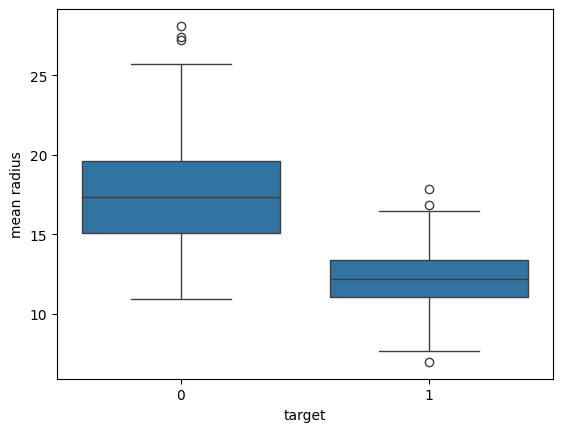

In [63]:
sns.boxplot(
    data = df,
    x = 'target',
    y = 'mean radius'
)

plt.show()

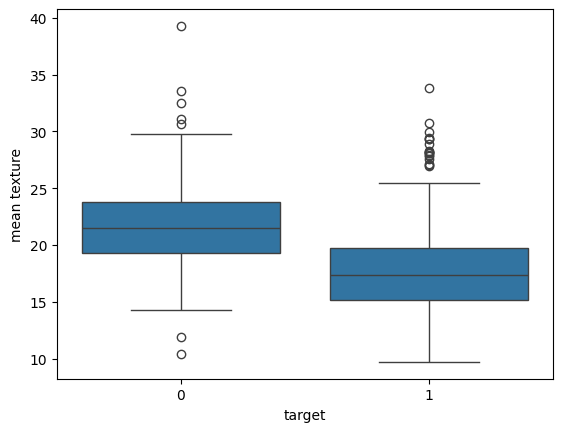

In [64]:
sns.boxplot(
    data = df,
    x = 'target',
    y = 'mean texture'
)

plt.show()

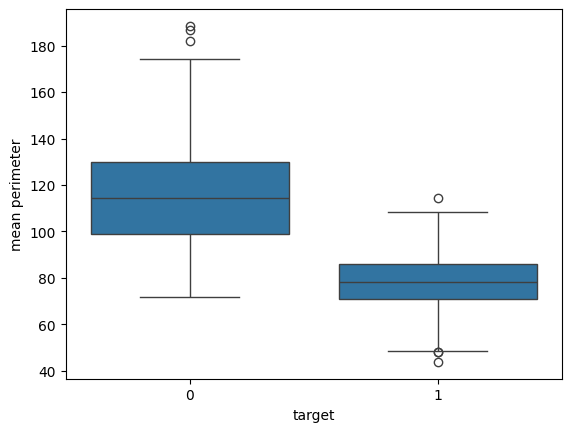

In [65]:
sns.boxplot(
    data = df,
    x = 'target',
    y = 'mean perimeter'
)

plt.show()

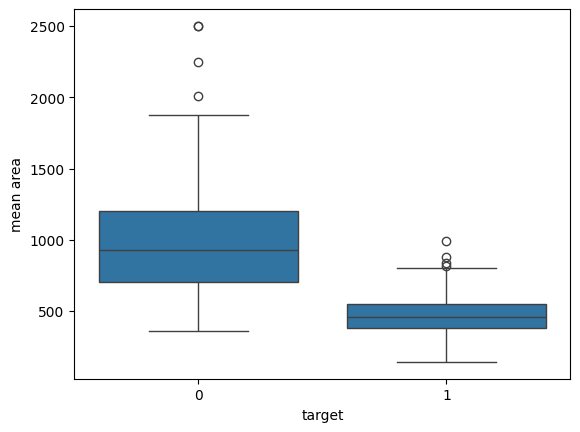

In [66]:
sns.boxplot(
    data = df,
    x = 'target',
    y = 'mean area'
)

plt.show()

In [67]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


##Answer:





1. 31 features including target column.
2. This is a classification problem. because the target column is only takes two values.

3. There are 569 data points.

4. There is not any null values as "print(f"Null values : {( df.isnull().sum() > 0 ).sum()}")" equals 0.

5. All 30 features are Quantitative or Numeical. There is not any categorical feature exist.

6. As every feature is Numerical. No encoding required.

7. The heatmap shows that mean, standard error and worst versions of the same measurement are highly correlated with each other.

8. The boxplot shows that, malignant tumors tend to have higher mean radius, texture and perimeter than benign. From the histplot we can observe that, size related features mean radius, perimeter, & area provide strong separability between the two classes, making them highly effective predictors for the classification model.

#2. Dataset pre-processing (15 marks)

1. Provide code
2. Discuss the pre processing steps you applied and why?


## Answer:


   

In [68]:
# 1.

numeric_feature = df.select_dtypes(
    include = ['int64', 'float64']
).columns

numeric_feature

features_with_outliers = []

for col in numeric_feature:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]

    if outliers > 0:
        print(f"'{col}' : {outliers}")
        features_with_outliers.append(col)

print(f"All features containing outliers: {features_with_outliers}")

'mean radius' : 14
'mean texture' : 7
'mean perimeter' : 13
'mean area' : 25
'mean smoothness' : 6
'mean compactness' : 16
'mean concavity' : 18
'mean concave points' : 10
'mean symmetry' : 15
'mean fractal dimension' : 15
'radius error' : 38
'texture error' : 20
'perimeter error' : 38
'area error' : 65
'smoothness error' : 30
'compactness error' : 28
'concavity error' : 22
'concave points error' : 19
'symmetry error' : 27
'fractal dimension error' : 28
'worst radius' : 17
'worst texture' : 5
'worst perimeter' : 15
'worst area' : 35
'worst smoothness' : 7
'worst compactness' : 16
'worst concavity' : 12
'worst symmetry' : 23
'worst fractal dimension' : 24
All features containing outliers: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity

In [69]:
X = df.drop('target', axis = True)
y = df['target']
X
y

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

I kept all outliers. Extreme biological measurements ( large area, high concavity) indicate highly malignant tumors that the model must learn to detect.
There is also encoding is not needed because all feature is numeric and target already in binary. Then i used Standard Scaler for ensuring fair comparison across all model.

#3.Feature selection and Dataset splitting (10 marks)

1. Which features you wanna keep ? Justify and drop and rest or apply any other feature engineering step
2. Perform Train test split

## Answer:



Im dropping feature which is almost perfectly correlated with another. Size metrics like radius, perimeter, and area are highly redundant. Keeping all of them confuses models.

In [70]:
redundant_features = ['mean perimeter', 'mean area', 'worst perimeter', 'worst area',
                       'perimeter error', 'area error']

X_red = X.drop(columns = redundant_features)
X_red

,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,...,symmetry error,fractal dimension error,worst radius,worst texture,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,...,0.03003,0.006193,25.380,17.33,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,...,0.01389,0.003532,24.990,23.41,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,...,0.02250,0.004571,23.570,25.53,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,...,0.05963,0.009208,14.910,26.50,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,...,0.01756,0.005115,22.540,16.67,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,...,0.01114,0.004239,25.450,26.40,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,...,0.01898,0.002498,23.690,38.25,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,...,0.01318,0.003892,18.980,34.12,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,...,0.02324,0.006185,25.740,39.42,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    X_red,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

X_train
display(X_test)
y_train
display(y_test)

,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,...,symmetry error,fractal dimension error,worst radius,worst texture,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
256,19.55,28.77,0.09260,0.20630,0.17840,0.11440,0.1893,0.06232,0.8426,1.1990,...,0.01936,0.005252,25.05,36.27,0.1281,0.53290,0.4251,0.19410,0.2818,0.10050
428,11.13,16.62,0.08151,0.03834,0.01369,0.01370,0.1511,0.06148,0.1415,0.9671,...,0.02009,0.002377,11.68,20.29,0.1030,0.06219,0.0458,0.04044,0.2383,0.07083
501,13.82,24.49,0.11620,0.16810,0.13570,0.06759,0.2275,0.07237,0.4751,1.5280,...,0.02434,0.006995,16.01,32.94,0.1794,0.39660,0.3381,0.15210,0.3651,0.11830
363,16.50,18.29,0.09686,0.08468,0.05862,0.04835,0.1495,0.05593,0.3389,1.4390,...,0.01694,0.002001,18.13,25.45,0.1338,0.16790,0.1663,0.09123,0.2394,0.06469
564,21.56,22.39,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,...,0.01114,0.004239,25.45,26.40,0.1410,0.21130,0.4107,0.22160,0.2060,0.07115
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,20.26,23.03,0.09078,0.13130,0.14650,0.08683,0.2095,0.05649,0.7576,1.5090,...,0.02657,0.004411,24.22,31.59,0.1190,0.35390,0.4098,0.15730,0.3689,0.08368
128,15.10,16.39,0.11500,0.18070,0.11380,0.08534,0.2001,0.06467,0.4309,1.0680,...,0.02353,0.004984,16.11,18.33,0.1386,0.28830,0.1960,0.14230,0.2590,0.07779
257,15.32,17.27,0.13350,0.22840,0.24480,0.12420,0.2398,0.07596,0.6592,1.0590,...,0.01884,0.008660,17.73,22.66,0.1765,0.45030,0.4429,0.22290,0.3258,0.11910
228,12.62,23.97,0.07903,0.07529,0.05438,0.02036,0.1514,0.06019,0.2449,1.0660,...,0.01365,0.003407,14.20,31.31,0.1227,0.34540,0.3911,0.11800,0.2826,0.09585


,target
256,0
428,1
501,0
363,1
564,0
...,...
95,0
128,1
257,0
228,1


#4.  Pipeline Creation (Supervised) (10 marks)

Select 2 models of your choice and build 2 pipelines for them

## Answer:

In [76]:
pipe_lr = Pipeline([
  ( 'scaler', StandardScaler() ),
  ( 'model', LogisticRegression( max_iter = 500, random_state = 42 ) )
])

pipe_rf = Pipeline([
  ( 'scaler', StandardScaler() ),
  ( 'model', RandomForestClassifier( n_estimators = 300, random_state = 42 ) )
])

pipe_lr

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=500, random_state=42))])

In [77]:
pipe_rf

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 RandomForestClassifier(n_estimators=300, random_state=42))])

# 5. Model Training (5 marks)

Train those 2 models



## Answer:

In [79]:
pipe_lr.fit( X_train, y_train )

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=500, random_state=42))])

In [80]:
pipe_rf.fit( X_train, y_train )

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 RandomForestClassifier(n_estimators=300, random_state=42))])

#6. Model selection/Comparison analysis (15 marks)
* Bar chart showcasing prediction accuracy of all models (for classification)
* Precision, recall comparison of each model. (for classification)
* Confusion Matrix (for classification)
* R2 score and Loss  (for regression)

Compare the results of all models based on all of the above described metrics. Why do you think this model performed better than the other one for this dataset?

# Answer:

In [84]:
y_pred_lr = pipe_lr.predict( X_test )

y_pred_rf = pipe_rf.predict( X_test )

In [212]:
print("Classification Report for Logistic Regression\n")

print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

Classification Report for Logistic Regression

              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [213]:
print("Classification Report for RandomForestClassifier\n")

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Classification Report for RandomForestClassifier

              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



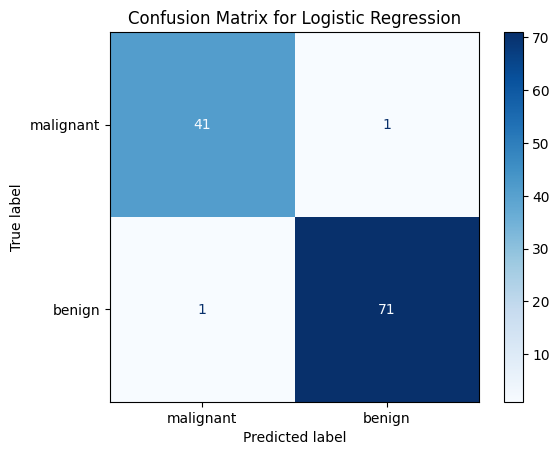

In [93]:
cm1 = confusion_matrix(
    y_test,
    y_pred_lr
)

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm1,
    display_labels=['malignant', 'benign']
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix for Logistic Regression")
plt.show()

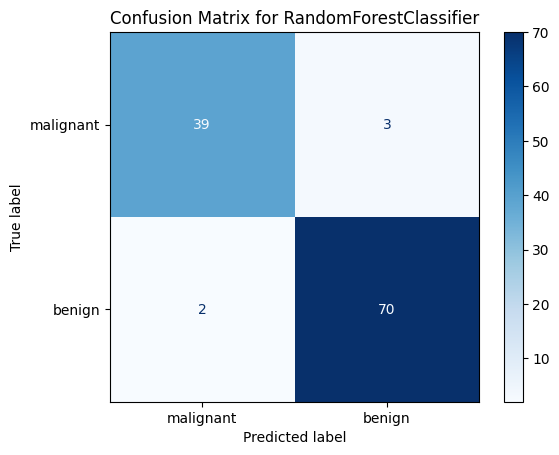

In [94]:
cm2 = confusion_matrix(
    y_test,
    y_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm2,
    display_labels=['malignant', 'benign']
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix for RandomForestClassifier")
plt.show()

The Logistic Regression model performs better than Random Forest. We can see the overall accuracy of Logistic Regression is 98% where the the accuracy of Random Forest is 96%.

Also, The Random Forest Classifier generated 3 False Negatives & 2 False positives. Whereas Logistic Regression minimized the error.

Logistic Regression performs better on the dataset cause it highly linear relationship with the target variable.

# 7. Treating the problem as Unsupervised (20 marks) ( Explore the topic as you wish )

1. Treat the problem as a unsupervised problem and perform any unsupervised model and evalute the result
2. Which method worked better? supervised or unsupervised approach and why?

# Answer:

In [96]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [214]:
np.set_printoptions(suppress = True)

pca_full = PCA(n_components = None)

X_pca_full = pca_full.fit_transform( X_scaled )

explained = pca_full.explained_variance_ratio_

explained

array([0.44272026, 0.18971182, 0.09393163, 0.06602135, 0.05495768,
       0.04024522, 0.02250734, 0.01588724, 0.01389649, 0.01168978,
       0.00979719, 0.00870538, 0.00804525, 0.00523366, 0.00313783,
       0.00266209, 0.00197997, 0.00175396, 0.00164925, 0.00103865,
       0.0009991 , 0.00091465, 0.00081136, 0.00060183, 0.00051604,
       0.00027259, 0.00023002, 0.00005298, 0.00002496, 0.00000443])

In [215]:
cum_variance = np.cumsum(explained)

cum_variance


array([0.44272026, 0.63243208, 0.72636371, 0.79238506, 0.84734274,
       0.88758796, 0.9100953 , 0.92598254, 0.93987903, 0.95156881,
       0.961366  , 0.97007138, 0.97811663, 0.98335029, 0.98648812,
       0.98915022, 0.99113018, 0.99288414, 0.9945334 , 0.99557204,
       0.99657114, 0.99748579, 0.99829715, 0.99889898, 0.99941502,
       0.99968761, 0.99991763, 0.99997061, 0.99999557, 1.        ])

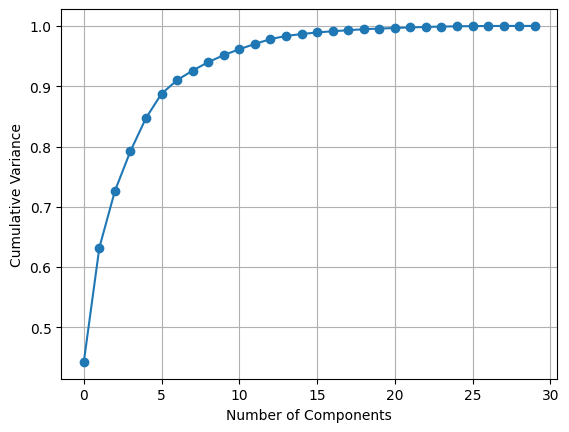

In [217]:
plt.plot(cum_variance, marker = 'o')

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.grid()
plt.show()

In [218]:
pca = PCA(n_components = 10, random_state = 42)
pca

PCA(n_components=10, random_state=42)

In [219]:
X_pca = pca.fit_transform(X_scaled)

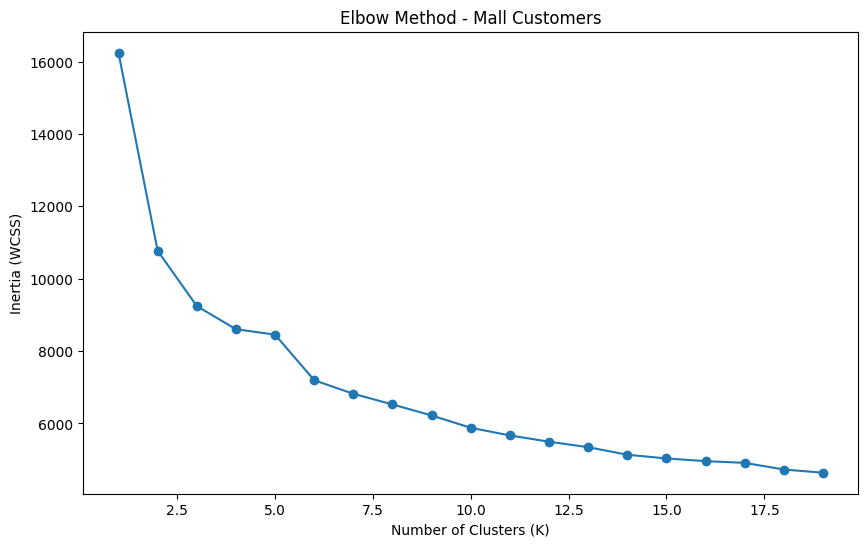

K=1: inertia=16243.28
K=2: inertia=10770.71
K=3: inertia=9242.66
K=4: inertia=8602.62
K=5: inertia=8453.21
K=6: inertia=7192.75
K=7: inertia=6818.51
K=8: inertia=6523.90
K=9: inertia=6219.42
K=10: inertia=5879.05
K=11: inertia=5667.46
K=12: inertia=5494.55
K=13: inertia=5342.92
K=14: inertia=5134.36
K=15: inertia=5031.47
K=16: inertia=4957.53
K=17: inertia=4909.31
K=18: inertia=4725.77
K=19: inertia=4637.39


In [220]:
inertias = []

for k in range(1, 20) :
  km = KMeans(
      n_clusters = k,
      init = 'k-means++',
      random_state = 42
  )

  km.fit(X_pca)
  inertias.append(km.inertia_)

plt.figure(figsize = (10, 6))
plt.plot(range(1, 20), inertias, marker = 'o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method - Mall Customers")

plt.show()

for k, i in zip(range(1,20), inertias):
    print(f"K={k}: inertia={i:.2f}")

In [221]:
kmeans = KMeans(
    n_clusters = 2,
    init = "k-means++",
    random_state = 42
)

kmeans.fit(X_pca)


KMeans(n_clusters=2, random_state=42)

In [222]:
kmeans_labels = kmeans.fit_predict(X_pca)

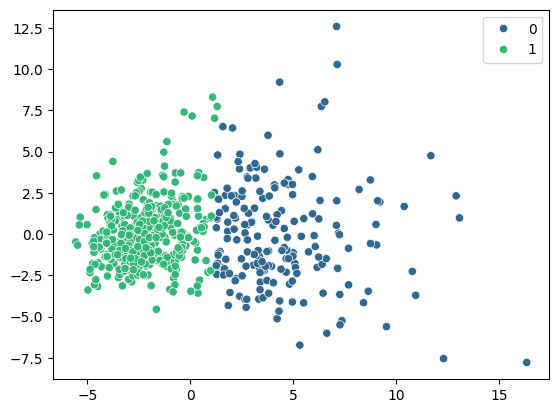

In [211]:
sns.scatterplot(
    data = df,
    x = X_pca[:, 0],
    y = X_pca[:, 1],
    hue = kmeans_labels,
    palette = 'viridis'
)

plt.show()

In [223]:
dbscan = DBSCAN(
    eps = 3,
    min_samples = 8
)

In [224]:
dbscan.fit(X_pca)

DBSCAN(eps=3, min_samples=8)

In [225]:
label_dbscan = dbscan.labels_

label_dbscan

array([-1,  0,  0, -1,  0,  0,  0,  0,  0, -1,  0,  0, -1,  0,  0,  0,  0,
        0,  0,  0,  0,  0, -1,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0, -1,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,
       -1,  0,  0, -1,  0,  0,  0,  0, -1, -1, -1,  0,  0,  0, -1, -1,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  0,  0, -1,  0,  0,  0, -1,  0,  0,  0, -1,  0,  0,
       -1,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0, -1,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0, -1, -1,
        0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0, -1,  0,
        0,  0,  0,  0,  0,  0, -1,  0,  0,  0, -1, -1,  0,  0,  0,  0,  0,
        0,  0,  0, -1,  0, -1,  0,  0,  0, -1,  0,  0,  0,  0,  0, -1, -1,
        0,  0,  0,  0,  0,  0,  0,  0, -1, -1, -1,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0

<Axes: >

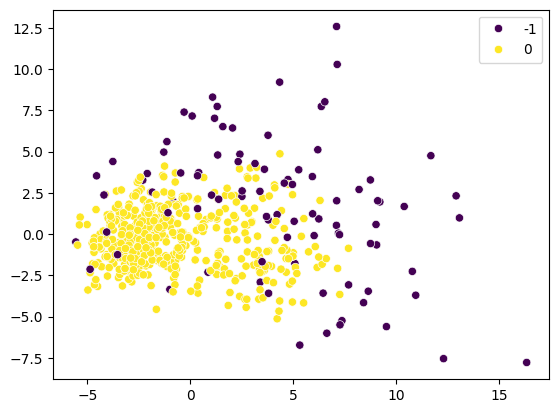

In [226]:
sns.scatterplot(
    x = X_pca[:, 0],
    y = X_pca[:, 1],
    hue = label_dbscan,
    palette = 'viridis'
)

In KMeans if we take n_clusters = 2, it may still struggle to perfectly separate malignant and benign cases.
On the otherside DBSCAN fails to capture the data structure entirely, labeling most of it as noise.

The supervised models (98% and 96% accuracy) clearly outperform clustering because they are trained with a specific goal learning to distinguish malignant from benign cases.

#8. Self Reflection on this machine learning course (10 marks)

Explain the hardest and the easiest topic of this course according to you in a intuitive way (you may also provide real world implementation , necessity etc along with the explaination)

##Answer:




Easiest for me:

EDA, preprocessing, and scaling felt the most easier to me among everything in this course. Cleaning up data, checking for nulls, scaling features are interesting. Same with Linear Regression, Logistic Regression, K-Means, and PCA, these models just made sense in my head once I saw them work on real data.


Hardest for me:

Decision Tree, Random Forest, and SVM took me a lot longer to actually get comfortable with. But DBSCAN is most frustrating cause choosing eps and min_samples is little bit confusing for me. I need to give more time on these topics.
